#### Série: DuckDB Masterclass
**Ordem sugerida de leitura:** 4 de 14


📚 **Material de apoio — Laboratórios práticos no Jupyter Notebook**

Acompanhe os conceitos deste artigo com exemplos SQL, exercícios e laboratórios da DuckDB Masterclass.

🔗 [Acessar os laboratórios no GitHub](https://github.com/aestevaomoraes/duckdb-masterclass)

# DuckDB Masterclass — Capítulo 04
## Leitura direta de Parquet e Friendly SQL

**Edição-piloto para autoaprendizagem e publicação** · [Série no GitHub](https://github.com/aestevaomoraes/duckdb-masterclass)

**Pré-requisitos:** SQL intermediário, Python, DuckDB e Pandas. Dados sintéticos, sem serviços externos.

**Roteiro:** entender o formato → gerar arquivo Parquet → consultar diretamente → aplicar Friendly SQL → validar as interpretações.

## 04.1 — Objetivos e diagnóstico

Ao final você poderá: distinguir leitura direta de importação persistente; consultar Parquet com `read_parquet`; utilizar `GROUP BY ALL`, `SELECT * EXCLUDE` e `SELECT * REPLACE`; e explicar o limite da expressão **zero-copy**.

**Pergunta inicial:** é necessário executar `CREATE TABLE` para analisar o conteúdo de um Parquet no DuckDB?    
**R:** O DuckDB permite executar consultas diretamente sobre arquivos Parquet. Uma tabela persistente pode ser útil em outros cenários, mas não é obrigatória para essa leitura.

## 04.2 — Conceito essencial

**Ler sem importar:** o DuckDB pode consultar um arquivo Parquet diretamente, sem materializá-lo antes em uma tabela. Isso não significa que cada etapa seja *zero-copy*: leitura em disco, descompressão, buffers e conversões podem ocorrer.

**Nota:** `Zero-copy` significa usar os dados onde já estão na memória, sem duplicá-los. Ler um arquivo direto (como um Parquet) quase sempre cria cópias, porque os bytes precisam ser descomprimidos, decodificados e convertidos para o formato interno do motor. Só há zero-copy quando o dado já está na forma exata que o motor usa.


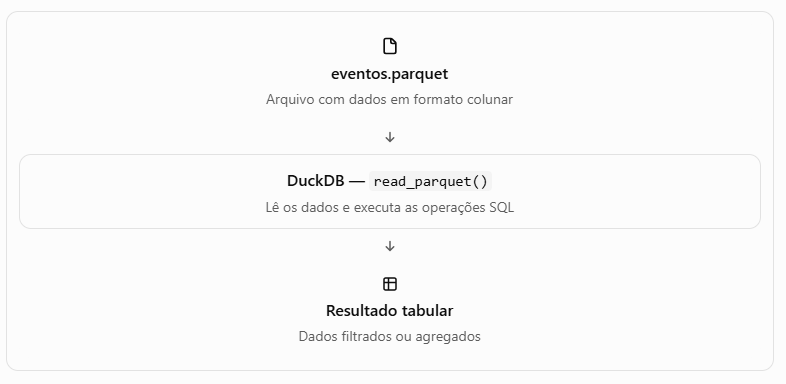



``` python
SELECT setor, COUNT(*) AS quantidade
FROM read_parquet('eventos.parquet')
GROUP BY setor;
```
*Nesse caso, `read_parquet()` funciona como uma fonte de dados consultável pelo SQL. Não precisamos executar `CREATE TABLE` antes.*

**Três recursos do DuckDB (Friendly SQL) para simplificar consultas**    
- `GROUP BY ALL` agrupa pelas expressões não agregadas da seleção.
- `EXCLUDE` remove colunas de uma projeção;
- `REPLACE` recalcula colunas mantendo seu nome.

*Esses três recursos são específicos do `DuckDB` e não fazem parte do SQL padrão. Se o código precisar rodar em outro banco, como PostgreSQL ou SQL Server, será preciso escrever as colunas explicitamente.*

## 04.3 — Preparação reproduzível

Criaremos arquivos exclusivamente em uma pasta temporária. Não há credenciais, downloads ou dados privados.

**Importante:** execute o notebook em ordem, num kernel limpo.

In [20]:
import duckdb
import tempfile
from pathlib import Path
from IPython.display import display

con = duckdb.connect(":memory:")
pasta_temp = tempfile.TemporaryDirectory()
caminho_parquet = Path(pasta_temp.name) / "eventos.parquet"
print("DuckDB:", duckdb.__version__)
print("Arquivo de laboratório: eventos.parquet")


DuckDB: 2.0.0
Arquivo de laboratório: eventos.parquet


#### 🧠 O que cada comando faz?

- `duckdb.connect(":memory:")`	Cria um banco DuckDB temporário na memória RAM.
- `tempfile.TemporaryDirectory()`	Cria um diretório temporário para os arquivos do laboratório.
- `Path(...) / "eventos.parquet"`	Define o caminho do arquivo Parquet que vamos gerar.
- `duckdb.__version__`	Confirma a versão instalada do DuckDB.

## 04.4 — Laboratório A: gerar um Parquet sintético

**Cenário:** o time operacional recebeu 60 eventos técnicos distribuídos em três setores.

**Hipótese:** podemos gerar um Parquet a partir de um conjunto sintético e verificar sua contagem.

In [21]:
con.execute("""
CREATE TABLE eventos_origem AS
SELECT i AS id,
       'SETOR_' || CAST(i % 3 AS VARCHAR) AS setor,
       CAST(i % 80 + 20 AS INTEGER) AS valor
FROM range(60) t(i)
""")
con.execute(f"COPY eventos_origem TO '{caminho_parquet.as_posix()}' (FORMAT PARQUET)")
assert caminho_parquet.exists()
assert con.execute('SELECT COUNT(*) FROM eventos_origem').fetchone()[0] == 60
print('Arquivo Parquet criado; 60 eventos sintéticos.')


Arquivo Parquet criado; 60 eventos sintéticos.


**Interpretação:** `COPY` gerou o arquivo uma vez; a próxima consulta será feita **diretamente no Parquet**, sem executar `CREATE TABLE` para o conteúdo lido.

#### 🔬 Entendendo o código do notebook
O laboratório utiliza três operações principais:

- `range(60)`	Gera 60 identificadores, de 0 a 59.
- `i % 3`	Distribui os eventos entre três setores.
- `COPY ... (FORMAT PARQUET)`	Exporta a tabela DuckDB para um arquivo Parquet.
- Duas verificações `assert:`   A primeira verifica se o arquivo foi criado. A segunda confirma que a tabela possui 60 registros.

## 04.5 — Laboratório B: consultar Parquet sem importar

Agora vamos investigar a principal característica deste capítulo: **consultar diretamente um arquivo Parquet usando SQL, sem criar outra tabela**

**Hipótese:** o total de registros lidos do arquivo será igual ao total da tabela de origem.

In [22]:
consulta = f"""
SELECT
    setor,
    COUNT(*) AS n,
    SUM(valor) AS total
FROM read_parquet('{caminho_parquet.as_posix()}')
GROUP BY ALL
ORDER BY setor
"""

res_parquet = con.execute(consulta).df()

display(res_parquet)

assert res_parquet['n'].sum() == 60

print('Leitura direta validada: 60 eventos.')


,setor,n,total
0,SETOR_0,20,970.0
1,SETOR_1,20,990.0
2,SETOR_2,20,1010.0


Leitura direta validada: 60 eventos.


**Ponto de engenharia:** leitura direta evita uma etapa de importação persistente. Não é prova de cópia zero em toda a trajetória dos bytes nem de desempenho superior sem benchmark controlado.

#### 🧠 Pontos principais


- `read_parquet()`	Consulta diretamente o arquivo Parquet.
- `COUNT(*)`	Conta os eventos de cada setor.
- `SUM(valor)`	Soma os valores dos eventos por setor.
- `GROUP BY ALL`	Agrupa pela coluna não agregada setor.
- `.df()`	Converte o resultado em DataFrame Pandas.

## 04.6 — Laboratório C: `EXCLUDE` e `REPLACE`

Agora estudaremos dois recursos do Friendly SQL que simplificam a transformação de dados.

**Hipótese:** poderemos ocultar `id` e transformar `valor` na projeção sem alterar os dados de origem.
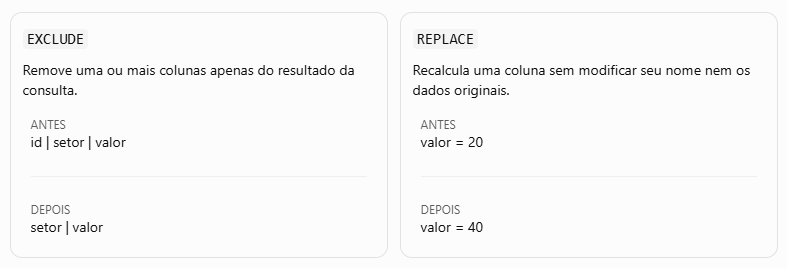


In [23]:
q_exclude = f"SELECT * EXCLUDE (id) FROM read_parquet('{caminho_parquet.as_posix()}') ORDER BY setor, valor LIMIT 5"
q_replace = f"SELECT * REPLACE (valor * 2 AS valor) FROM read_parquet('{caminho_parquet.as_posix()}') ORDER BY id LIMIT 5"

res_exclude = con.execute(q_exclude).df()
res_replace = con.execute(q_replace).df()
display(res_exclude)
display(res_replace)
assert 'id' not in res_exclude.columns
assert res_replace.loc[0,'valor'] == 40
assert con.execute(f"SELECT MIN(valor) FROM read_parquet('{caminho_parquet.as_posix()}')").fetchone()[0] == 20
print('Projeções validadas; Parquet de origem preservado.')


,setor,valor
0,SETOR_0,20
1,SETOR_0,23
2,SETOR_0,26
3,SETOR_0,29
4,SETOR_0,32


,id,setor,valor
0,0,SETOR_0,40
1,1,SETOR_1,42
2,2,SETOR_2,44
3,3,SETOR_0,46
4,4,SETOR_1,48


Projeções validadas; Parquet de origem preservado.


**Interpretação:** `REPLACE` mudou o resultado da consulta, não o arquivo original; sua coluna continua se chamando `valor`.

#### 🔬 O que seu experimento comprovou

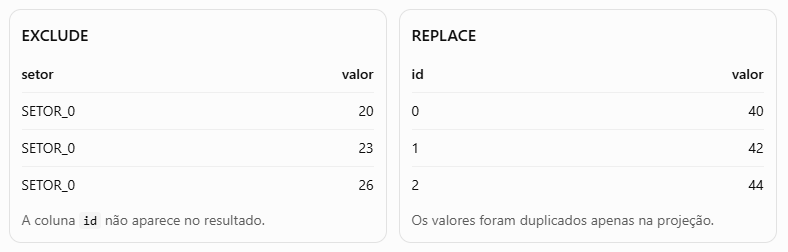



> ⚠️ **AVISO — Erro ao localizar o arquivo Parquet**
>
> Se, durante a execução deste laboratório, aparecer uma mensagem semelhante a:
>
> ```text
> IOException: IO Error:
> No files found that match the pattern ".../eventos.parquet"
> ```
>
> Isso significa que o DuckDB não conseguiu localizar o arquivo Parquet no caminho informado.
>
> **Por que isso acontece?**
>
> Este laboratório utiliza um banco DuckDB em memória (`:memory:`) e uma pasta temporária (`tempfile.TemporaryDirectory()`).
>
> Se a sessão do Jupyter for reiniciada, a conexão for recriada ou a pasta temporária for removida, os recursos necessários poderão deixar de estar disponíveis.
>
> **✅ Como resolver**
>
> 1. Execute novamente a seção **04.3 — Preparação reproduzível**, para recriar a conexão e a pasta temporária.
> 2. Execute a seção **04.4 — Gerar um Parquet sintético**, para recriar a tabela e o arquivo `eventos.parquet`.
> 3. Execute a seção **04.5 — Consultar Parquet sem importar**, para confirmar a leitura dos 60 registros.
> 4. Retorne à seção **04.6** e execute novamente o laboratório.
>
> **Resultado esperado:**
>
> ```text
> Projeções validadas; Parquet de origem preservado.
> ```
>
> **💡 Boa prática de engenharia:** notebooks que dependem de tabelas em memória e arquivos temporários devem ser executados na sequência correta. Isso facilita a reprodução dos experimentos e evita erros decorrentes de recursos temporários indisponíveis.


## 04.7 — Desafio profissional

**Missão:** identificar o setor com a maior soma de `valor`, calcular a média por evento e verificar se há empates.

Sua missão é produzir um relatório que responda:
1. Qual setor possui a maior soma de valor?
2. Quantos eventos existem em cada setor?
3. Qual é a média de valor por evento?
4. Existe empate entre os setores?

**Antes de ver a solução:** escreva sua consulta usando `read_parquet`, `GROUP BY ALL` e ordenação explícita; especifique o resultado esperado.

In [18]:
# Solução de referência — execute após tentar
resultado_setores = con.execute(f"""
SELECT setor,
       COUNT(*) AS eventos,
       SUM(valor) AS soma_valor,
       ROUND(AVG(valor), 2) AS media_valor
FROM read_parquet('{caminho_parquet.as_posix()}')
GROUP BY ALL
ORDER BY soma_valor DESC, setor
""").df()
display(resultado_setores)
assert resultado_setores['eventos'].sum() == 60
assert resultado_setores['soma_valor'].sum() == con.execute('SELECT SUM(valor) FROM eventos_origem').fetchone()[0]


,setor,eventos,soma_valor,media_valor
0,SETOR_2,20,1010.0,50.5
1,SETOR_1,20,990.0,49.5
2,SETOR_0,20,970.0,48.5


**Leitura executiva:** a ordenação determina a apresentação; o segundo critério (`setor`) torna o resultado estável em caso de empate. Compare a soma entre origem e Parquet para validar completude.


#### 🧠 Pontos principais do código

Neste laboratório, utilizamos o DuckDB para identificar o setor com maior valor acumulado, calcular indicadores e organizar os resultados.

| Comando | Finalidade |
|---|---|
| `read_parquet()` | Consulta diretamente o arquivo Parquet, sem importação prévia para outra tabela. |
| `COUNT(*) AS eventos` | Conta a quantidade de eventos por setor. |
| `SUM(valor) AS soma_valor` | Calcula o valor acumulado de cada setor. |
| `AVG(valor)` | Calcula a média dos valores por evento em cada setor. |
| `ROUND(AVG(valor), 2)` | Arredonda a média para duas casas decimais. |
| `GROUP BY ALL` | Agrupa automaticamente pelas expressões selecionadas que não possuem agregação, neste caso `setor`. |
| `ORDER BY soma_valor DESC, setor` | Ordena pela maior soma e utiliza o nome do setor como critério secundário em caso de empate. |
| `.df()` | Transforma o resultado da consulta em um DataFrame Pandas. |
| `display()` | Apresenta o DataFrame no Jupyter Notebook. |
| `assert` | Verifica se a quantidade e a soma dos valores correspondem aos dados de origem. |

#### 📊 Interpretação dos resultados

| Setor | Eventos | Soma dos valores | Média por evento |
|---|---:|---:|---:|
| SETOR_2 | 20 | 1.010 | 50,50 |
| SETOR_1 | 20 | 990 | 49,50 |
| SETOR_0 | 20 | 970 | 48,50 |

**Conclusões operacionais:**

- **SETOR_2** apresenta o maior valor acumulado: 1.010.
- Todos os setores possuem 20 eventos.
- A diferença entre os totais decorre dos valores registrados, não da quantidade de eventos.
- Não existe empate entre os setores.
- As verificações `assert` confirmam a quantidade total de eventos e a igualdade da soma entre a tabela de origem e o Parquet.

> **💡 Aprendizado de engenharia:** uma análise confiável não termina quando o SQL produz resultados. É necessário verificar a granularidade, validar as agregações e interpretar corretamente os indicadores.


## 04.8 — Autoavaliação

1. Qual a diferença entre `read_parquet` e `CREATE TABLE AS SELECT`?
2. O que `GROUP BY ALL` faz diante de uma agregação?
3. `SELECT * REPLACE` modifica o arquivo de origem?
4. Por que leitura direta não é necessariamente *zero-copy*?
5. Como provar que o arquivo contém todas as linhas esperadas?

<details><summary>Gabarito comentado</summary>

1. O primeiro consulta o arquivo diretamente; o segundo cria uma tabela persistente ou temporária, conforme o banco e a definição.
2. Agrupa pelas expressões não agregadas da seleção.
3. Não: altera somente a projeção da consulta.
4. Porque podem existir I/O, descompressão, cópias e transformações no processamento.
5. Comparando contagens e totais da origem com os da leitura direta, incluindo verificações de nulos quando aplicáveis.

</details>

## 04.9 — Referências, reprodução e limpeza

- [DuckDB — Parquet Overview](https://duckdb.org/docs/stable/data/parquet/overview)
- [DuckDB — GROUP BY ALL](https://duckdb.org/docs/stable/sql/query_syntax/groupby)
- [DuckDB — SELECT](https://duckdb.org/docs/stable/sql/query_syntax/select)
- [DuckDB — Friendly SQL](https://duckdb.org/docs/stable/sql/dialect/friendly_sql)

**Reprodução:** kernel limpo, execute as células em ordem, confira os `assert` e salve as saídas úteis. O caminho real dos arquivos não é impresso.

**Limpeza:** o arquivo foi criado em pasta temporária e não deve ser publicado no GitHub.

**Estado:** piloto preparado e validado estruturalmente; execução integral no DuckDB **ainda pendente de validação no kernel do projeto**.